# Titanic — Group survival feature

**Question:** notebook 03 suggested that ~83% CV accuracy is a ceiling of the current features, not of the model.
Does *new information* move it?

**The feature.** Families and friends often travelled on one ticket and shared their fate. For each passenger,
`GroupSurvival` is the survival rate of the **other** known passengers who share their ticket or their family
(surname + fare); `GroupKnown` says whether any such passenger exists. Passengers without a known group member get
0.5 ("no information").

**The danger.** The feature is computed from the target `Survived`. Done carelessly it hands the answer to the
model. This notebook shows two careless versions on purpose, then the correct one.

1. What the feature looks like.
2. The leakage trap: two wrong ways and the right way.
3. Honest comparison: logistic regression and tuned XGBoost, with and without the feature.
4. Error analysis and test coverage.
5. Submission files.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.insert(0, str(Path("../src").resolve()))
from titanic.data import load_raw
from titanic.features import GroupSurvivalEncoder, make_preprocessor

SEED = 42
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
REPORT_DIR = Path("../reports")
SUBMISSION_DIR = Path("../submissions")

# Parallelism stays inside the models (threads): worker processes would not find the `titanic` package,
# which is only on this notebook's sys.path.
N_THREADS = 8

sns.set_theme(style="whitegrid", palette="deep")


def save_fig(fig, name):
    """Save a figure to reports/figures for the README and the blog post."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


train = load_raw(DATA_DIR / "train.csv")
test = load_raw(DATA_DIR / "test.csv")
X = train.drop(columns="Survived")
y = train["Survived"]
print(f"X: {X.shape}, y: {y.shape}, test: {test.shape}")

X: (891, 11), y: (891,), test: (418, 11)


In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(name, model, data=None):
    """Score `model` with 5-fold CV on the shared folds and store the fold scores."""
    scores = cross_validate(model, X if data is None else data, y, cv=cv, scoring="accuracy",
                            return_train_score=True, return_estimator=True)
    results[name] = scores
    print(f"{name:<40} CV accuracy {scores['test_score'].mean():.3f} ± {scores['test_score'].std():.3f}")
    return scores


def make_model(estimator, group_survival=False):
    """Shared preprocessing (optionally with the group survival step) followed by `estimator`."""
    return Pipeline([("prep", make_preprocessor(group_survival=group_survival)), ("model", estimator)])


def out_of_fold(name, data=None):
    """Predict every row with the fold model that did not see it (reuses the models fitted in `evaluate`)."""
    data = X if data is None else data
    pred = pd.Series(0, index=X.index)
    for fold_model, (_, valid_idx) in zip(results[name]["estimator"], cv.split(X, y)):
        pred.iloc[valid_idx] = fold_model.predict(data.iloc[valid_idx])
    return pred

## 1. What the feature looks like

To describe the feature honestly, each passenger gets the value a model would see during cross-validation: the
encoder is fitted on the 4 training folds and applied to the 5th (*out-of-fold* values).

In [3]:
oof_group = pd.DataFrame(index=X.index, columns=["GroupSurvival", "GroupKnown"], dtype=float)
for train_idx, valid_idx in cv.split(X, y):
    encoder = GroupSurvivalEncoder().fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_group.iloc[valid_idx] = encoder.transform(X.iloc[valid_idx])[["GroupSurvival", "GroupKnown"]].to_numpy()


def describe_group(row):
    """Readable bucket for the out-of-fold feature value."""
    if row["GroupKnown"] == 0:
        return "no known group member"
    if row["GroupSurvival"] == 0:
        return "all known members died"
    if row["GroupSurvival"] == 1:
        return "all known members survived"
    return "mixed"


buckets = train.assign(GroupBucket=oof_group.apply(describe_group, axis=1))
bucket_table = buckets.groupby("GroupBucket")["Survived"].agg(count="size", survival_rate="mean").round(3)
bucket_table

,count,survival_rate
GroupBucket,,
all known members died,152,0.171
all known members survived,134,0.709
mixed,40,0.800
no known group member,565,0.335


In [4]:
pd.crosstab([buckets["Gender"], buckets["GroupBucket"]], buckets["Survived"], normalize="index").round(3)

Survived                               0      1
Gender GroupBucket                             
female all known members died      0.696  0.304
       all known members survived  0.000  1.000
       mixed                       0.077  0.923
       no known group member       0.203  0.797
male   all known members died      0.940  0.060
       all known members survived  0.574  0.426
       mixed                       0.429  0.571
       no known group member       0.837  0.163

The second table splits the buckets by gender, which matters: gender alone already explains most of the survival
rate, so the feature only adds information if it separates passengers **within** the same gender.

## 2. The leakage trap

Three ways to put the feature into a logistic regression:

- **Leak A, own label included:** the group rate is computed on all 891 passengers and includes the passenger's
  own `Survived`. A passenger alone on a ticket gets a "group rate" equal to their own label.
- **Leak B, leave-one-out but computed before CV:** each passenger's own label is left out, but the rates are
  computed once on all 891 passengers. A passenger in the validation fold then gets a value built from the
  labels of group members who are *also* in the validation fold. On Kaggle those labels are unknown, so CV
  measures a situation that never happens at prediction time.
- **Correct:** the encoder is a Pipeline step. In every fold it only sees the training fold's labels, and on the
  training rows it leaves the passenger's own label out.

Leak A and B are computed outside the Pipeline, so their step is replaced by `"passthrough"` and the
precomputed columns are used as they are.

In [5]:
x_leak_own = GroupSurvivalEncoder().fit(X, y).transform(X)        # transform: own label included
x_leak_before_cv = GroupSurvivalEncoder().fit_transform(X, y)     # leave-one-out, but on all rows at once

leaky_logreg = make_model(LogisticRegression(max_iter=1000), group_survival=True).set_params(
    prep__group_survival="passthrough")

evaluate("Logistic regression", make_model(LogisticRegression(max_iter=1000)))
evaluate("LEAK A: own label included", leaky_logreg, data=x_leak_own)
evaluate("LEAK B: computed before CV", leaky_logreg, data=x_leak_before_cv)
evaluate("Logistic regression + group", make_model(LogisticRegression(max_iter=1000), group_survival=True));

Logistic regression                      CV accuracy 0.831 ± 0.010
LEAK A: own label included               CV accuracy 0.983 ± 0.006


LEAK B: computed before CV               CV accuracy 0.844 ± 0.015


Logistic regression + group              CV accuracy 0.841 ± 0.016


Both leaky versions report a CV score that the model cannot reach on Kaggle, because Kaggle's test labels are not
available to build the feature. The only number worth trusting is the one from the Pipeline version.
**The leaky scores are not saved to `cv_results.csv`.**

## 3. Honest comparison: tuned XGBoost with and without the feature

Same nested cross-validation as notebook 03: the inner `GridSearchCV` (4 folds) picks the setting, the outer
5 folds score the whole procedure. The group step is part of the Pipeline, so it is refitted inside every inner
and outer fold.

In [6]:
inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
xgb_grid = {
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.03, 0.1],
    "model__n_estimators": [100, 300],
    "model__min_child_weight": [1, 5],
}


def make_xgb_search(group_survival):
    """Nested-CV-ready grid search over the XGBoost settings of notebook 03."""
    estimator = XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=N_THREADS)
    return GridSearchCV(make_model(estimator, group_survival), xgb_grid, cv=inner_cv, scoring="accuracy")


evaluate("XGBoost (tuned)", make_xgb_search(group_survival=False))
evaluate("XGBoost (tuned) + group", make_xgb_search(group_survival=True));

XGBoost (tuned)                          CV accuracy 0.832 ± 0.025


XGBoost (tuned) + group                  CV accuracy 0.837 ± 0.007


## 4. Comparison

In [7]:
summary = pd.DataFrame({
    name: {
        "cv_mean": s["test_score"].mean(),
        "cv_std": s["test_score"].std(),
        "train_mean": s["train_score"].mean(),
    }
    for name, s in results.items()
}).T
summary["train_cv_gap"] = summary["train_mean"] - summary["cv_mean"]
summary = summary.round(4)

honest = summary.loc[~summary.index.str.startswith("LEAK")]
all_results = pd.read_csv(REPORT_DIR / "cv_results.csv", index_col="model")
all_results = pd.concat([all_results.drop(index=honest.index, errors="ignore"), honest])
all_results.to_csv(REPORT_DIR / "cv_results.csv", index_label="model")
summary.sort_values("cv_mean", ascending=False)

,cv_mean,cv_std,train_mean,train_cv_gap
LEAK A: own label included,0.9832,0.0062,0.9868,0.0036
LEAK B: computed before CV,0.8440,0.0149,0.8510,0.0070
Logistic regression + group,0.8406,0.0162,0.9240,0.0833
XGBoost (tuned) + group,0.8373,0.0073,0.9231,0.0859
XGBoost (tuned),0.8316,0.0248,0.8864,0.0548
Logistic regression,0.8305,0.0099,0.8339,0.0034


**Train accuracy is not meaningful for the group models.** `cross_validate` measures it with `predict` on the
training rows, which uses `transform`, so each training passenger's own label is inside their feature. The
CV column is the one to read.

In [8]:
fold_scores = pd.DataFrame({name: s["test_score"] for name, s in results.items() if not name.startswith("LEAK")})
fold_scores.index = [f"fold {i + 1}" for i in range(len(fold_scores))]
fold_scores["LR: group - no group"] = fold_scores["Logistic regression + group"] - fold_scores["Logistic regression"]
fold_scores["XGB: group - no group"] = fold_scores["XGBoost (tuned) + group"] - fold_scores["XGBoost (tuned)"]
fold_scores.round(3)

,Logistic regression,Logistic regression + group,XGBoost (tuned),XGBoost (tuned) + group,LR: group - no group,XGB: group - no group
fold 1,0.844,0.844,0.866,0.844,0.000,-0.022
fold 2,0.826,0.831,0.843,0.831,0.006,-0.011
fold 3,0.815,0.815,0.798,0.826,0.000,0.028
fold 4,0.837,0.860,0.843,0.843,0.022,0.000
fold 5,0.831,0.854,0.809,0.843,0.022,0.034


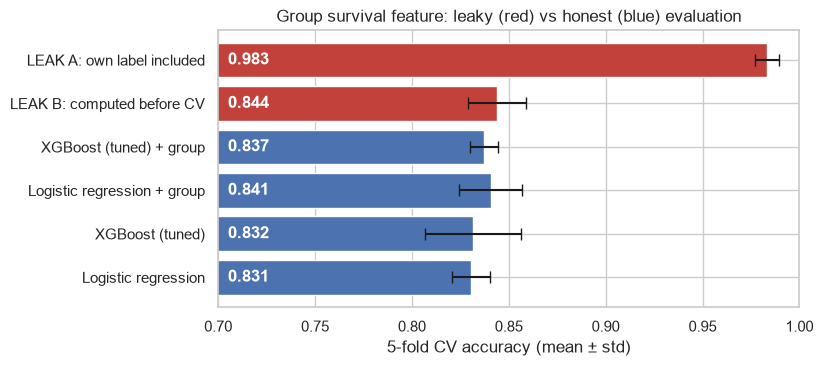

In [9]:
order = ["LEAK A: own label included", "LEAK B: computed before CV", "XGBoost (tuned) + group",
         "Logistic regression + group", "XGBoost (tuned)", "Logistic regression"]
plot_data = summary.loc[order[::-1]]
colors = ["#c2413b" if name.startswith("LEAK") else "#4c72b0" for name in plot_data.index]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(plot_data.index, plot_data["cv_mean"], xerr=plot_data["cv_std"], capsize=4, color=colors)
for i, name in enumerate(plot_data.index):
    ax.text(0.705, i, f"{plot_data.loc[name, 'cv_mean']:.3f}", va="center", color="white", weight="bold")
ax.set_xlim(0.7, 1.0)
ax.set_xlabel("5-fold CV accuracy (mean ± std)")
ax.set_title("Group survival feature: leaky (red) vs honest (blue) evaluation")
save_fig(fig, "group_feature_comparison")
plt.show()

## 5. Error analysis

In [10]:
oof = pd.DataFrame({name: out_of_fold(name) for name in ["Logistic regression", "Logistic regression + group"]})
group_accuracy = pd.concat(
    {name: train.assign(correct=(oof[name] == y)).pivot_table(
        index="Gender", columns="Pclass", values="correct", aggfunc="mean")
     for name in oof.columns},
    axis=0,
).round(3)
group_accuracy

Pclass                                  1      2      3
                            Gender                     
Logistic regression         female  0.968  0.895  0.653
                            male    0.631  0.926  0.893
Logistic regression + group female  0.968  0.908  0.743
                            male    0.615  0.917  0.888

In [11]:
changed = oof[oof.iloc[:, 0] != oof.iloc[:, 1]]
fixed = (changed.iloc[:, 1] == y[changed.index]).sum()
print(f"Adding the feature changes {len(changed)} predictions: {fixed} become right, {len(changed) - fixed} become wrong.")
buckets.loc[changed.index].assign(
    now_right=(changed.iloc[:, 1] == y[changed.index]),
).groupby(["Gender", "GroupBucket"])["now_right"].agg(changed="size", now_right="sum")

Adding the feature changes 45 predictions: 27 become right, 18 become wrong.


changed  now_right
Gender GroupBucket                                   
female all known members died           22         18
       all known members survived        1          1
       no known group member             1          0
male   all known members died            4          2
       all known members survived       12          4
       mixed                             1          0
       no known group member             4          2

## 6. Does the test set look like the validation folds?

The feature only helps passengers with a known group member. In CV, a validation passenger can only find group
members in the other 4 folds (~713 passengers); on Kaggle, a test passenger finds them among all 891 training
passengers, but test passengers whose group travelled mostly in the test set find nobody. If the share of
passengers with a known group differs a lot, CV will misjudge the feature's value on Kaggle.

In [12]:
valid_coverage = []
for train_idx, valid_idx in cv.split(X, y):
    encoder = GroupSurvivalEncoder().fit(X.iloc[train_idx], y.iloc[train_idx])
    valid_coverage.append(encoder.transform(X.iloc[valid_idx])["GroupKnown"].mean())
test_group = GroupSurvivalEncoder().fit(X, y).transform(test)

print(f"Known group member, validation folds: {np.mean(valid_coverage):.3f} (per fold {np.round(valid_coverage, 3)})")
print(f"Known group member, Kaggle test set:  {test_group['GroupKnown'].mean():.3f}")
test_group.loc[test_group["GroupKnown"] == 1, "GroupSurvival"].describe().round(3)

Known group member, validation folds: 0.366 (per fold [0.352 0.348 0.416 0.354 0.36 ])
Known group member, Kaggle test set:  0.409


count    171.000
mean       0.511
std        0.466
min        0.000
25%        0.000
50%        0.500
75%        1.000
max        1.000
Name: GroupSurvival, dtype: float64

## 7. Submission files

In [13]:
final_models = {
    "04_logreg_group.csv": make_model(LogisticRegression(max_iter=1000), group_survival=True),
    "04_xgb_group.csv": make_xgb_search(group_survival=True),
}
previous = {
    "04_logreg_group.csv": "02_logreg.csv",
    "04_xgb_group.csv": "03_xgb.csv",
}
for file_name, model in final_models.items():
    model.fit(X, y)
    submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": model.predict(test)})
    assert submission.shape == (418, 2) and submission["Survived"].isin([0, 1]).all()
    submission.to_csv(SUBMISSION_DIR / file_name, index=False)
    before = pd.read_csv(SUBMISSION_DIR / previous[file_name])
    changed = int((submission["Survived"].to_numpy() != before["Survived"].to_numpy()).sum())
    print(f"{file_name}: predicted survival {submission['Survived'].mean():.3f}, "
          f"{changed} test predictions differ from {previous[file_name]}")
print("XGBoost setting chosen on all passengers:",
      {k.replace("model__", ""): v for k, v in final_models["04_xgb_group.csv"].best_params_.items()})

04_logreg_group.csv: predicted survival 0.373, 28 test predictions differ from 02_logreg.csv


04_xgb_group.csv: predicted survival 0.354, 24 test predictions differ from 03_xgb.csv
XGBoost setting chosen on all passengers: {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 100}


## 8. Findings

**Scores (5-fold stratified CV, same folds as notebooks 02–03)**

| Model | CV accuracy | Change |
|---|---|---|
| Logistic regression | 0.831 ± 0.010 | |
| Logistic regression + group | **0.841 ± 0.016** | +1.0 |
| XGBoost (tuned, nested CV) | 0.832 ± 0.025 | |
| XGBoost (tuned, nested CV) + group | 0.837 ± 0.007 | +0.6 |
| *Leak A: own label included* | *0.983 ± 0.006* | not a real score |
| *Leak B: leave-one-out computed before CV* | *0.844 ± 0.015* | not a real score |

**The leakage trap, in numbers.** Including the passenger's own label (leak A) produces 98% accuracy: obviously
wrong, easy to spot. Computing the leave-one-out rates once on all passengers before CV (leak B) inflates the score
by only 0.3 points over the honest version. That is the dangerous kind of leak: the number looks plausible, and
without the honest Pipeline version for comparison nobody would notice.

**The feature helps logistic regression, honestly measured.** +1.0 point on average, and fold by fold it is never
worse (0.0, +0.6, 0.0, +2.2, +2.2). This is the first change in the project that moves the ~83% plateau, and it
comes from new information, not from a more flexible model. For tuned XGBoost the average gain is smaller (+0.6)
and the folds go both ways (−2.2 to +3.4), so for trees the effect is not established.

**Where it helps: women in 3rd class.** Their out-of-fold accuracy rises from 65.3% to 74.3%, the group logistic
regression struggled with most. The feature changes 45 predictions: 27 become right, 18 become wrong. The biggest
win is women whose known group members all died (22 changed, 18 now right): a woman in 3rd class travelling with a
family that perished is likely to have perished too. The biggest loss is men whose known group members all
survived (12 changed, only 4 now right): those survivors are probably mostly the women and children of the group (not
checked here), which would say little about the man himself.

**What it looks like.** Only about a third of passengers have a known group member during CV. Among them, survival
is 17% when all known members died and 71% when all survived, against 34% for passengers with no known member.

**Does it transfer to Kaggle?** A known group member exists for 36.6% of validation passengers and 40.9% of test
passengers, so the feature is available on the test set at least as often as in CV. The new submissions change 28
(logistic regression) and 24 (XGBoost) of the 418 test predictions compared with notebooks 02 and 03.

**Caveats.** Train accuracy is inflated for the group models (see section 4) and should be ignored. A 1-point CV
gain is about two passengers per fold; the consistent fold-by-fold direction is what makes it credible, and the
Kaggle score of `04_logreg_group.csv` is the next check.